### Imports
Imports libraries that are used

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import ast
import wfdb

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score,
    f1_score, 
    confusion_matrix, 
    classification_report,
    ConfusionMatrixDisplay
)

### Prepare data
Mostly used example code from "example_physionet.py" that followed in the dataset. <br>

Loads the PTB-XL metadata and ECG recordings. <br>

Diagnostic annotations are mapped into five superclass categories, which are converted into numerical labels. <br>

The ECG signals are normalized independently for each lead, recordings containing NaN values are removed, and the data is reshaped into the format expected by Conv1D. <br>

The dataset is divided using the official PTB-XL folds: folds 1–8 for training, fold 9 for validation, and fold 10 for testing.

In [ ]:
# Path to PTB-XL dataset
path = "ptbxl/"

# Load metadata
Y = pd.read_csv(
    path + "ptbxl_database.csv",
    index_col="ecg_id"
)

Y.scp_codes = Y.scp_codes.apply(lambda x: ast.literal_eval(x))
print (Y.head())

sampling_rate = 100  # Hz

# Load ECG signals. Each record contains 12 leads sampled over time.
def load_raw_data(df, sampling_rate, path):
    if sampling_rate == 100:
        data = [wfdb.rdsamp(path + f) for f in df.filename_lr]
    else:
        data = [wfdb.rdsamp(path + f) for f in df.filename_hr]
    data = np.array([signal for signal, meta in data])
    return data

X = load_raw_data(Y, sampling_rate, path = path)
print (X.shape)

# Map the detailed SCP annotations to diagnostic superclass labels.
agg_df = pd.read_csv(path + "scp_statements.csv", index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]

def aggregate_diagnostic(y_dic):
    tmp = []
    for key in y_dic.keys():
        if key in agg_df.index:
            tmp.append(agg_df.loc[key].diagnostic_class)
    return sorted(set(tmp))

Y["diagnostic_superclass"] = Y.scp_codes.apply(aggregate_diagnostic)

# Keep records with at least one superclass, and use the first one as the target.
Y["single_label"] = Y["diagnostic_superclass"].apply(lambda x: x[0] if len(x) > 0 else "UNKNOWN")

valid_indices = Y["single_label"] != "UNKNOWN"

Y = Y[valid_indices].copy()
X = X[valid_indices.values]   # NumPy-array for CNN

print(Y["single_label"].value_counts())

# Convert text labels to integer class IDs for PyTorch's classification loss.
label_map = {
    "NORM": 0,
    "MI": 1,
    "STTC": 2,
    "CD": 3,
    "HYP": 4,
    }

y = Y["single_label"].map(label_map).values

print(y[:10])

# Normalize each lead independently to reduce differences in signal scale.
def normalize_ecg(signal):
    mean = np.mean(signal, axis=0)
    std = np.std(signal, axis=0)
    normalized_signal = (signal - mean) / (std + 1e-8)
    return normalized_signal

X = np.array([normalize_ecg(ecg) for ecg in X])

# Remove recordings with nan values (flat or missing lead)
good = ~np.isnan(X).any(axis=(1, 2))
print("Removed:", (~good).sum(), "recording(s)")
X = X[good]
Y = Y[good]
y = y[good]

ecg = X[0]

print(ecg.mean(axis=0))
print(ecg.std(axis=0))

# Conv1d expects tensors shaped as (batch, channels/leads, time samples).
X = np.transpose(X, (0, 2, 1))
print (X.shape)

# Use the official PTB-XL folds: 1-8 train, 9 validation, and 10 test.
X_train = X[Y.strat_fold < 9]
Y_train = y[Y.strat_fold < 9]
X_val = X[Y.strat_fold == 9]
Y_val = y[Y.strat_fold == 9]
X_test = X[Y.strat_fold == 10]
Y_test = y[Y.strat_fold == 10]

print("Training:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Testing:", X_test.shape, Y_test.shape)


### Data batches
Creates data batches for training and validation. <br>

Converts the training and validation data into PyTorch tensors and pairs each ECG recording with its corresponding label. <br>

DataLoaders divide the datasets into batches of 32 recordings. <br>

Training data is shuffled, while the validation data keeps its original order.

In [ ]:
# Convert NumPy arrays into tensors and pair each ECG with its class label.
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
Y_train_tensor = torch.tensor(Y_train, dtype=torch.long)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
Y_val_tensor = torch.tensor(Y_val, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, Y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, Y_val_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

### CNN Model
Defines the 1D CNN architecture, which uses convolutional and pooling layers to extract patterns from the ECG signals. <br>

The fully connected layers use these extracted features to classify each recording into one of the five diagnostic categories. <br>

Focal Loss and class weight is used as the criterion in this version. <br>

Cross-Entropy Loss is kept as commented-out alternatives for comparison.

In [12]:
class ECG_CNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Convolutions learn local waveform patterns across the 12 leads.
        self.conv1 = nn.Conv1d(12, 32, 7)
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(32, 64, 5)

        self.fc1 = nn.Linear(64 * 246, 128)
        self.fc2 = nn.Linear(128, 5)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))

        x = torch.flatten(x, 1)
        x = torch.relu(self.fc1(x))

        return self.fc2(x)

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None):
        super().__init__()
        self.gamma = gamma
        self.weight = weight

    def forward(self, outputs, targets):
        # Down-weight easy examples so training focuses more on difficult cases.
        ce_loss = nn.functional.cross_entropy(outputs, targets, reduction="none")
        pt = torch.exp(-ce_loss)
        loss = ((1 - pt) ** self.gamma) * ce_loss

        if self.weight is not None:
            loss = loss * self.weight[targets]
            
        return loss.mean()

    
model = ECG_CNN()
counts = np.bincount(Y_train)
weights = torch.tensor(len(Y_train) / (5 * counts), dtype=torch.float32)

criterion = nn.CrossEntropyLoss()
#criterion = FocalLoss(gamma=2.0, weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)

### Train the model

Trains the CNN for a maximum of 30 epochs using the training dataset. <br>

After each epoch, the model is evaluated using the validation dataset. <br>

Early stopping prevents unnecessary training if the validation loss does not improve after 5 consecutive epochs. <br>

TThe best epoch with the lowest validation loss is then selected.

In [13]:

train_losses = []
val_losses = []

best_val = float('inf')
best_state = None
patience = 5 
bad_epochs = 0

for epoch in range(30):
    # Train the model
    model.train()
    train_loss = 0.0

    for X_batch, Y_batch in train_loader:
        outputs = model(X_batch)
        loss = criterion(outputs, Y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    # Evaluate on validation data without updating weights
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for X_batch, Y_batch in val_loader:
            outputs = model(X_batch)
            loss = criterion(outputs, Y_batch)
            val_loss += loss.item()

    val_loss /= len(val_loader)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1}: "
        f"Train Loss = {train_loss:.4f}, "
        f"Validation Loss = {val_loss:.4f}"
    )

    if val_loss < best_val:
        best_val = val_loss
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
        bad_epochs = 0
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print("Early stopping at epoch", epoch + 1)
            break

model.load_state_dict(best_state)

Epoch 1: Train Loss = 1.0422, Validation Loss = 0.9624
Epoch 2: Train Loss = 0.8019, Validation Loss = 0.8920
Epoch 3: Train Loss = 0.6420, Validation Loss = 0.9522
Epoch 4: Train Loss = 0.4347, Validation Loss = 1.1200
Epoch 5: Train Loss = 0.2159, Validation Loss = 1.5022
Epoch 6: Train Loss = 0.0719, Validation Loss = 1.7821
Epoch 7: Train Loss = 0.0271, Validation Loss = 2.2168
Early stopping at epoch 7


<All keys matched successfully>

### Visualize loss

Plots the training and validation loss across epochs to visualize how the model learns. <br>

A vertical line indicates the epoch with the lowest validation loss, showing the epoch that was selected.

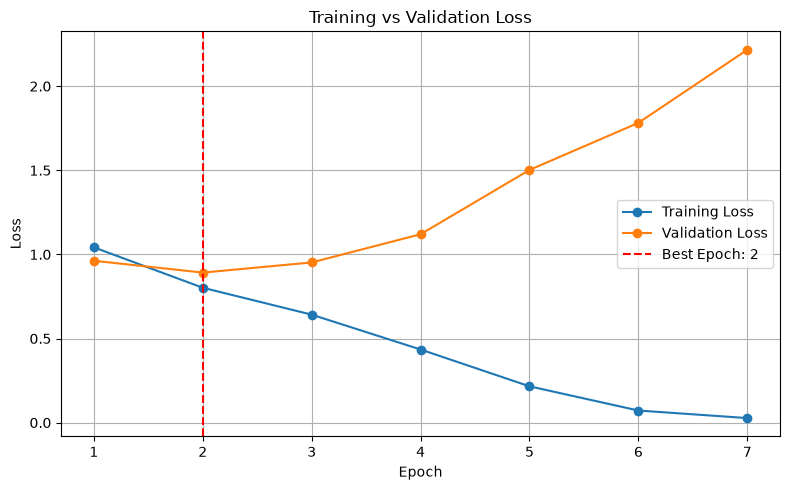

In [14]:
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")

best_epoch = val_losses.index(min(val_losses)) + 1
plt.axvline(best_epoch, color='r', linestyle='--', label=f'Best Epoch: {best_epoch}')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Test the model

Evaluates the selected model using the test dataset, which was not used during training or validation. <br>

Predictions are compared against the true labels using accuracy, precision, recall, and macro F1-score. <br>

A classification report provides per-class performance <br>

A confusion matrix visualizes correct and incorrect classifications across the five categories. <br>

Accuracy: 0.6562
Precision (Macro): 0.5725
Precision (Weighted): 0.6448
Recall (Macro): 0.5244
Recall (Weighted): 0.6562
F1 Score (Macro): 0.5373

Classification Report:
              precision    recall  f1-score   support

        NORM       0.72      0.92      0.80       916
          MI       0.49      0.39      0.44       317
        STTC       0.47      0.50      0.48       242
          CD       0.79      0.58      0.67       496
         HYP       0.40      0.24      0.30       187

    accuracy                           0.66      2158
   macro avg       0.57      0.52      0.54      2158
weighted avg       0.64      0.66      0.64      2158



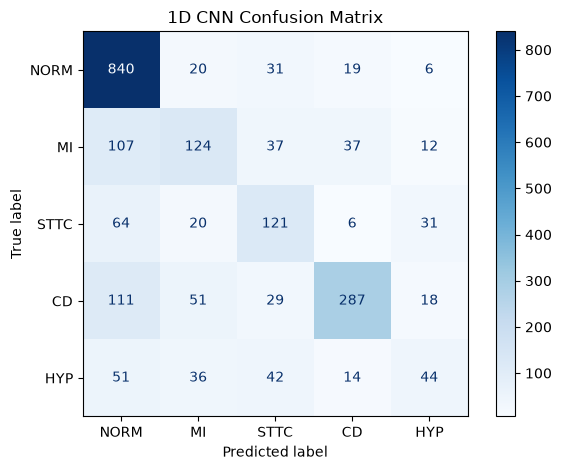

In [ ]:
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
Y_test_tensor = torch.tensor(Y_test, dtype=torch.long)

model.eval()

with torch.no_grad():
    outputs = model(X_test_tensor)
    predictions = torch.argmax(outputs, dim=1)

class_names = ["NORM", "MI", "STTC", "CD", "HYP"]
class_labels = [0, 1, 2, 3, 4]

y_true = Y_test_tensor.numpy()
y_pred = predictions.numpy()

accuracy = accuracy_score(y_true, y_pred)
precision_macro = precision_score(y_true, y_pred, average='macro', zero_division=0)
precision_weighted = precision_score(y_true, y_pred, average='weighted', zero_division=0)
recall_macro = recall_score(y_true, y_pred, average='macro', zero_division=0)
recall_weighted = recall_score(y_true, y_pred, average='weighted', zero_division=0)
f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)

print(f"Accuracy: {accuracy:.4f}")

print(f"Precision (Macro): {precision_macro:.4f}")
print(f"Precision (Weighted): {precision_weighted:.4f}")

print(f"Recall (Macro): {recall_macro:.4f}")
print(f"Recall (Weighted): {recall_weighted:.4f}")

print(f"F1 Score (Macro): {f1_macro:.4f}")

print ("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=class_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

disp.plot(cmap="Blues", values_format="d")
plt.title("1D CNN Confusion Matrix")
plt.tight_layout()
plt.show()